# 01 EDA: one store, intermittency, seasonality, events
Goal: build the long-format table for one store, then understand the demand before modeling.
Change `STORE` to any store id (CA_1, CA_2, TX_1, WI_1 ...).

In [2]:
import sys
sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import (load_calendar, load_prices, load_sales_wide,
                             sales_to_long, add_prices)

RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
STORE = "CA_1"

## 1. Build and save the long table

In [3]:
cal = load_calendar(RAW / "calendar.csv")
sales_wide = load_sales_wide(RAW / "sales_train_evaluation.csv", store_ids=[STORE])
prices = load_prices(RAW / "sell_prices.csv")

long = add_prices(sales_to_long(sales_wide, cal), prices)
long.to_parquet(PROC / f"{STORE.lower()}_long.parquet", index=False)
print(long.shape, long["date"].min().date(), long["date"].max().date(), long["id"].nunique(), "series")

(5918109, 17) 2011-01-29 2016-05-22 3049 series


## 2. Sanity checks
A missing price means the item was not on sale yet that week, so early zeros are "not launched", not "no demand".

In [4]:
print("rows with missing price:", round(long["sell_price"].isna().mean(), 3))
print("rows with zero sales:   ", round((long["sales"] == 0).mean(), 3))
long.groupby("cat_id")["sales"].agg(total="sum", mean_per_day="mean")

rows with missing price: 0.191
rows with zero sales:    0.638


,total,mean_per_day
cat_id,,
FOODS,5471661,1.961719
HOBBIES,892083,0.813451
HOUSEHOLD,1468504,0.722608


## 3. Intermittency classes (Syntetos-Boylan)
ADI = average days between sales, CV2 = squared variation of the non-zero sale sizes.
Smooth / erratic / intermittent / lumpy tells you which models make sense per series.

In [5]:
day_cols = [c for c in sales_wide.columns if c.startswith("d_")]
vals = sales_wide[day_cols].to_numpy(dtype=float)

rows = []
for row in vals:
    nz = np.flatnonzero(row)
    if len(nz) == 0:
        rows.append((np.nan, np.nan, np.nan))
        continue
    trimmed = row[nz[0]:]                      # ignore days before first sale
    demand = trimmed[trimmed > 0]
    adi = len(trimmed) / len(demand)
    cv2 = (demand.std() / demand.mean()) ** 2 if len(demand) > 1 else 0.0
    rows.append((adi, cv2, (trimmed == 0).mean()))

stats = pd.DataFrame(rows, columns=["adi", "cv2", "zero_share"], index=sales_wide["id"])
stats["class"] = np.select(
    [stats["adi"].isna(),
     (stats["adi"] < 1.32) & (stats["cv2"] < 0.49),
     (stats["adi"] < 1.32),
     (stats["cv2"] < 0.49)],
    ["no sales", "smooth", "erratic", "intermittent"],
    default="lumpy",
)
print(stats["class"].value_counts())
print("median zero share after first sale:", stats["zero_share"].median().round(3))

class
intermittent    2195
lumpy            544
smooth           234
erratic           76
Name: count, dtype: int64
median zero share after first sale: 0.579


## 4. Plots

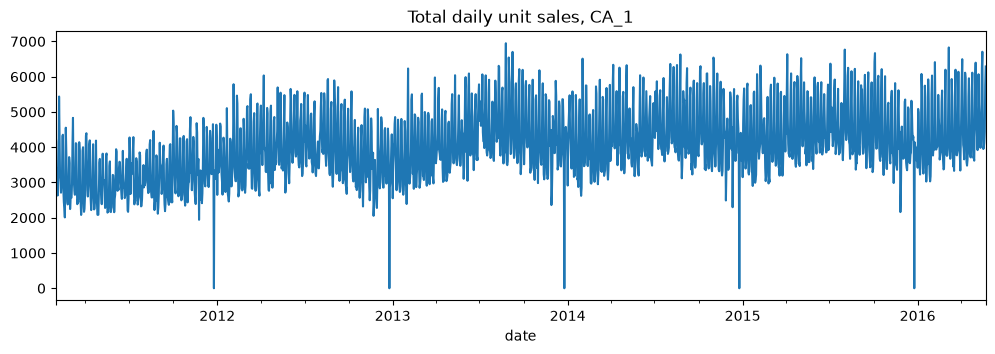

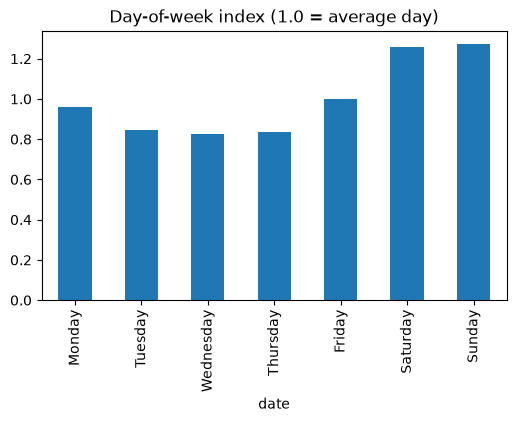

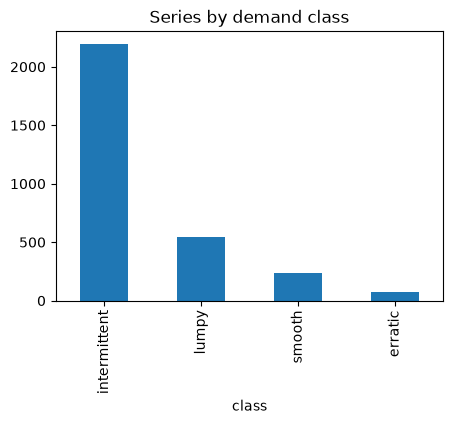

In [6]:
daily = long.groupby("date")["sales"].sum()

fig, ax = plt.subplots(figsize=(12, 3.5))
daily.plot(ax=ax)
ax.set_title(f"Total daily unit sales, {STORE}")
fig.savefig(FIG / "01_daily_total.png", dpi=150, bbox_inches="tight")

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = daily.groupby(daily.index.day_name()).mean().reindex(order)
fig, ax = plt.subplots(figsize=(6, 3.5))
(dow / dow.mean()).plot.bar(ax=ax)
ax.set_title("Day-of-week index (1.0 = average day)")
fig.savefig(FIG / "02_dow_index.png", dpi=150, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(5, 3.5))
stats["class"].value_counts().plot.bar(ax=ax)
ax.set_title("Series by demand class")
fig.savefig(FIG / "03_demand_classes.png", dpi=150, bbox_inches="tight")

## 5. Do events matter?
Compare each day to its 28-day centered average, then split by event vs non-event days.

In [7]:
ev = long.groupby("date").agg(sales=("sales", "sum"), event=("event_name_1", "first"))
ev["ratio"] = ev["sales"] / ev["sales"].rolling(28, center=True).mean()
print("avg ratio on event days:    ", ev.loc[ev["event"].notna(), "ratio"].mean().round(3))
print("avg ratio on non-event days:", ev.loc[ev["event"].isna(), "ratio"].mean().round(3))
ev.loc[ev["event"].notna()].groupby("event")["ratio"].mean().sort_values().round(2)

avg ratio on event days:     0.948
avg ratio on non-event days: 1.005


event
Christmas              0.00
Thanksgiving           0.58
NewYear                0.76
LentWeek2              0.81
NBAFinalsStart         0.81
LentStart              0.82
Halloween              0.83
ValentinesDay          0.90
IndependenceDay        0.92
Cinco De Mayo          0.94
StPatricksDay          0.95
NBAFinalsEnd           0.96
EidAlAdha              0.96
Ramadan starts         0.99
Chanukah End           0.99
Eid al-Fitr            1.00
PresidentsDay          1.02
ColumbusDay            1.02
MemorialDay            1.03
MartinLutherKingDay    1.03
Pesach End             1.04
OrthodoxChristmas      1.05
Easter                 1.05
Father's day           1.05
VeteransDay            1.05
Mother's day           1.07
Purim End              1.07
SuperBowl              1.22
LaborDay               1.22
OrthodoxEaster         1.26
Name: ratio, dtype: float64

## Takeaways (fill in)
- Weekly pattern:
- Share of intermittent / lumpy series:
- Events that move sales most:
- Modeling implication: